# ECE 535 — Head and Full-Body Movement Analysis

**Project:** Privacy and Behavioral Analysis of Mixed-Reality Sensor Data  
**Focus:** Liz's head/body movement analysis; this notebook starts with the available **Roma Tre head-movement data**.

Run the cells from top to bottom. Start with `head_movement_cleaned.csv`, produced by the November 7 preprocessing script. The data is not embedded in this notebook.

This notebook checks data quality, makes preliminary graphs, and evaluates participant identification across separate recordings. Sections 7–10 add a 20-person cross-task experiment. **A separate UTD-MHAD full-body study is added in sections 11–16. Those sections run independently and download their own skeleton data.** The saved head-study outputs are from November 17, 2026; rerunning sections 1–10 requires the cleaned head CSV. The full-body study was run on November 18, 2026.

References: [Head Movement Dataset](https://muse.uniroma3.it/headdataset/) · [Project head/body notes](https://docs.google.com/document/d/1Hmr76o8rYz2sX7e5DS92fqTuCSIGqG6AfKtG0P7tt9Y/edit)


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.25})
OUTPUT_DIR = Path("analysis_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)


## 1. Load your cleaned data

Set `DATA_PATH` to an existing CSV in your runtime, or leave it blank to choose the CSV from your computer. The cleaned CSV is about 207 MB, so uploading may take a little while.

For data already in Google Drive, mount Drive first in a separate code cell:
```python
from google.colab import drive
drive.mount('/content/drive')
```
Then set `DATA_PATH` to its `/content/drive/MyDrive/...` path. Your computer's `/Users/...` paths are not available inside Colab.


In [ ]:
DATA_PATH = ""  # Example: "/content/drive/MyDrive/ECE 535/head_movement_cleaned.csv"

if not DATA_PATH:
    from google.colab import files
    print("Choose head_movement_cleaned.csv")
    uploaded = files.upload()
    candidates = [name for name in uploaded if name.endswith(".csv")]
    if len(candidates) != 1:
        raise ValueError("Upload exactly one cleaned movement CSV, or set DATA_PATH explicitly.")
    DATA_PATH = candidates[0]
    del uploaded  # Release the extra in-memory copy.

columns = [
    "session", "participant_id", "task", "recording_file", "sample_index",
    "elapsed_seconds", "phase", "head_x", "head_y", "head_z",
    "time_delta_seconds", "speed", "acceleration_magnitude", "quality_flag",
]
categories = {name: "category" for name in ["session", "participant_id", "task", "recording_file", "phase", "quality_flag"]}
df = pd.read_csv(DATA_PATH, usecols=columns, dtype=categories)
print(f"Loaded {len(df):,} samples from {df['recording_file'].nunique():,} recordings.")
display(df.head())


Loaded 925,574 samples from 120 recordings.


,session,participant_id,task,recording_file,sample_index,elapsed_seconds,phase,head_x,head_y,head_z,time_delta_seconds,speed,acceleration_magnitude,quality_flag
0,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,0,0.0000,non_stress_1,0.01260,-0.00170,0.00744,NaN,NaN,NaN,NaN
1,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,1,0.0202,non_stress_1,0.01332,-0.00142,0.01144,0.0202,0.201679,NaN,NaN
2,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,2,0.0299,non_stress_1,0.01361,-0.00134,0.01180,0.0097,0.048366,10.776376,NaN
3,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,3,0.0551,non_stress_1,0.01443,-0.00077,0.01306,0.0252,0.063800,1.116512,NaN
4,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,4,0.0699,non_stress_1,0.01446,-0.00111,0.01323,0.0148,0.025764,3.351472,NaN


## 2. Data quality and coverage

The preprocessing retained duplicate timestamps and flagged them. Their undefined movement derivatives are missing, as are derivatives at recording starts. Keep these distinctions visible before drawing conclusions.

Coordinate units are preserved from the source dataset. Speed and acceleration below are in **dataset coordinate units per second** and **per second squared**. Finite-difference derivatives may be noisy.


In [ ]:
required_numbers = ["elapsed_seconds", "head_x", "head_y", "head_z", "speed", "acceleration_magnitude"]
quality_report = pd.DataFrame({
    "missing": df[required_numbers].isna().sum(),
    "nonfinite_present": {c: int((df[c].notna() & ~np.isfinite(df[c])).sum()) for c in required_numbers},
})
display(quality_report)
display(df["quality_flag"].astype("string").fillna("unflagged").value_counts().rename("samples"))

coverage = df.groupby(["session", "task"], observed=True).agg(
    participants=("participant_id", "nunique"),
    recordings=("recording_file", "nunique"),
    samples=("sample_index", "size"),
)
display(coverage)


,missing,nonfinite_present
elapsed_seconds,0,0
head_x,0,0
head_y,0,0
head_z,0,0
speed,375,0
acceleration_magnitude,750,0


quality_flag
unflagged              925319
duplicate_timestamp       255
Name: samples, dtype: Int64

participants  recordings  samples
session  task                                   
Session1 SCWT            60          60   389908
Session2 SCWT            20          20   129944
Session3 SCWT            20          20   129921
         MA              20          20   275801

## 3. Inspect one recording

Change `RECORDING` to any value in `df['recording_file'].unique()` to inspect a different recording. Displayed curves are sampled to keep plots responsive; later summaries use all valid samples.


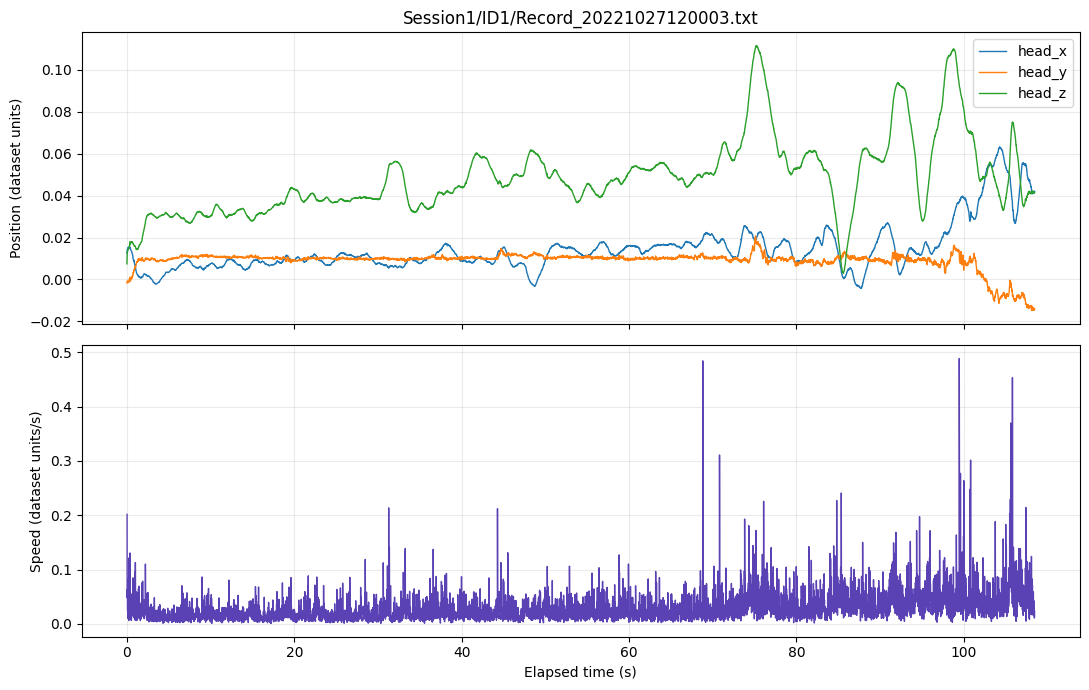

In [ ]:
RECORDING = str(df["recording_file"].iloc[0])
recording = df.loc[df["recording_file"] == RECORDING].sort_values("sample_index")
plot_data = recording.iloc[::max(1, len(recording) // 5000)]

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for axis in ["head_x", "head_y", "head_z"]:
    axes[0].plot(plot_data["elapsed_seconds"], plot_data[axis], label=axis, linewidth=1)
axes[0].set(ylabel="Position (dataset units)", title=RECORDING)
axes[0].legend()
axes[1].plot(plot_data["elapsed_seconds"], plot_data["speed"], color="#5b42b4", linewidth=1)
axes[1].set(xlabel="Elapsed time (s)", ylabel="Speed (dataset units/s)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "example_recording.png", dpi=160)
plt.show()


## 4. Summarize each recording and phase

Compute a median and upper percentile of speed and a median of acceleration for each recording/phase. Exclude flagged rows and nonfinite derivatives from these calculations; retain the original dataframe for inspection.

The phase labels come from the existing preprocessing timing rules: SCWT boundaries at 23 and 43 seconds; MA boundary at 60 seconds. **Verify these against the dataset protocol before using them in your report.** These labels describe task periods; they are not individual clinical stress measurements.


In [ ]:
valid = (
    df["quality_flag"].isna()
    & np.isfinite(df["speed"])
    & np.isfinite(df["acceleration_magnitude"])
)
movement = df.loc[valid]
phase_summary = movement.groupby(
    ["session", "participant_id", "task", "recording_file", "phase"], observed=True
).agg(
    valid_samples=("speed", "size"),
    median_speed=("speed", "median"),
    p95_speed=("speed", lambda s: s.quantile(0.95)),
    median_acceleration=("acceleration_magnitude", "median"),
).reset_index()
print(f"Included {valid.sum():,} of {len(df):,} samples with unflagged, finite speed and acceleration.")
display(phase_summary.head(15))


Included 924,824 of 925,574 samples with unflagged, finite speed and acceleration.


,session,participant_id,task,recording_file,phase,valid_samples,median_speed,p95_speed,median_acceleration
0,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,non_stress_1,1374,0.014464,0.046235,1.203650
1,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,non_stress_2,1187,0.016260,0.053957,1.355863
2,Session1,ID1,SCWT,Session1/ID1/Record_20221027120003.txt,stress,3926,0.026751,0.085058,2.035345
3,Session1,ID10,SCWT,Session1/ID10/Record_20221027174538.txt,non_stress_1,1376,0.013786,0.057492,1.144890
4,Session1,ID10,SCWT,Session1/ID10/Record_20221027174538.txt,non_stress_2,1200,0.014679,0.059416,1.306816
5,Session1,ID10,SCWT,Session1/ID10/Record_20221027174538.txt,stress,3917,0.042264,0.168585,2.925369
6,Session1,ID11,SCWT,Session1/ID11/Record_20221027175922.txt,non_stress_1,1365,0.023213,0.078928,1.677371
7,Session1,ID11,SCWT,Session1/ID11/Record_20221027175922.txt,non_stress_2,1198,0.025673,0.090227,1.892097
8,Session1,ID11,SCWT,Session1/ID11/Record_20221027175922.txt,stress,3909,0.028721,0.097651,2.223614
9,Session1,ID12,SCWT,Session1/ID12/Record_20221027181225.txt,non_stress_1,1372,0.013024,0.048425,0.925489


## 5. Compare phases descriptively

Each point is one recording/phase summary. The chart shows distributions of recording medians rather than treating every frame as an independent observation. Recordings from the same participant can still be related; this plot is descriptive and does not establish statistical significance or causality.


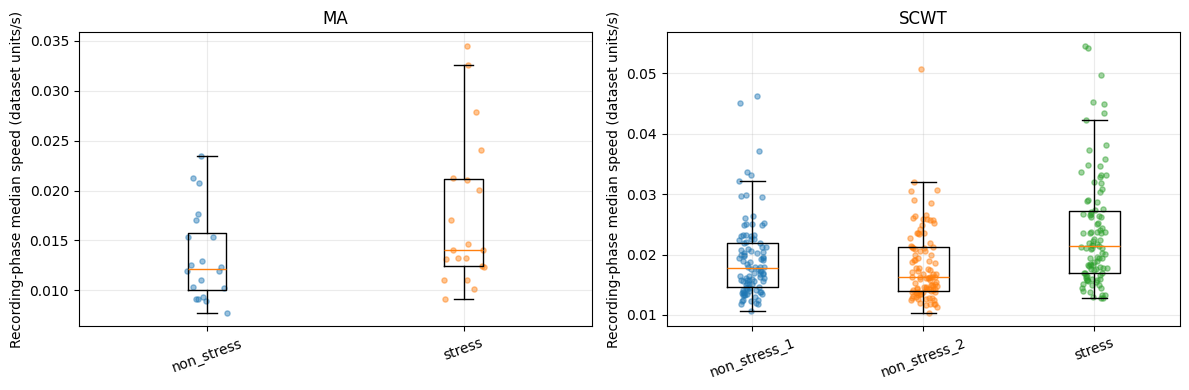

In [ ]:
tasks = sorted(phase_summary["task"].astype(str).unique())
if not tasks:
    raise ValueError("No valid recording/phase summaries; inspect data quality first.")
fig, axes = plt.subplots(1, len(tasks), figsize=(6 * len(tasks), 4), squeeze=False)
phase_order = ["non_stress_1", "non_stress_2", "non_stress", "stress"]
rng = np.random.default_rng(535)
for ax, task in zip(axes[0], tasks):
    subset = phase_summary.loc[phase_summary["task"] == task]
    phases = [p for p in phase_order if (subset["phase"] == p).any()]
    values = [subset.loc[subset["phase"] == p, "median_speed"].to_numpy() for p in phases]
    ax.boxplot(values, showfliers=False)
    for x, y in enumerate(values, start=1):
        ax.scatter(x + rng.uniform(-0.08, 0.08, size=len(y)), y, s=14, alpha=0.45)
    ax.set_xticks(range(1, len(phases) + 1))
    ax.set_xticklabels(phases, rotation=20)
    ax.set(title=task, ylabel="Recording-phase median speed (dataset units/s)")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "phase_speed_comparison.png", dpi=160)
plt.show()


## 6. Export and record findings

The next cell writes summary tables and bundles them with the figures. In Colab, download the ZIP from the Files panel when needed.


In [ ]:
import shutil

phase_summary.to_csv(OUTPUT_DIR / "recording_phase_summary.csv", index=False)
coverage.to_csv(OUTPUT_DIR / "data_coverage.csv")
quality_report.to_csv(OUTPUT_DIR / "data_quality.csv")
archive = shutil.make_archive("ece535_head_movement_results", "zip", OUTPUT_DIR)
print(f"Results saved to {Path(archive).resolve()}")


Results saved to /Users/lizfaulkner/Documents/Codex/2026-11-16/new-chat-2/work/execution/ece535_head_movement_results.zip


## 7. Participant identification — protocol and features

**Primary question:** Can movement summaries identify one of 20 enrolled people when the task changes?

- Use **Session3 only**: T1–T20 each have one SCWT and one MA recording. Other cohorts have only one recording per person and cannot support this separate-recording closed-set test.
- **Primary split:** train on all SCWT recordings, test on separate MA recordings. Reverse direction is a sensitivity analysis, not an independent replication.
- Use the first **100 seconds** of each recording, split into twenty **non-overlapping 5-second windows**. Keep the same duration and number of windows for each person/task. Require at least 200 usable samples and 4.8 seconds of observed span per window.
- Main predictors: **18 motion features** (per-axis standard deviation, IQR, range and endpoint displacement; median, 90th percentile and IQR of speed and acceleration magnitude). They remove fixed position offsets, but are not a complete normalization of body size, orientation or environment.
- A separate exploratory model adds three absolute-position means to check how sensitive identification is to position context.
- IDs, task, paths, timestamps, window number and phase labels are metadata, **never predictors**. Split by whole recording; fit any learned preprocessing on training recordings only.
- Fixed random forest settings: 300 trees, minimum leaf size 2, square-root feature selection, balanced subsampling, seed 535. No hyperparameter tuning on these test results. Uniform chance accuracy is **1/20 = 5%**.

These settings define a preliminary baseline, not an optimized biometric system. Do not choose a new model from these test results and report the same test as untouched validation.

Source: [dataset authors’ README](https://github.com/MUSEResearchGroup/stress-assessment-head-movement#dataset). The original study concerns stress, not participant identification. [Scikit-learn leakage guidance](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
import sklearn

SEED = 535
WINDOW_SECONDS = 5
SECONDS_PER_RECORDING = 100
EXPECTED_IDS = [f"T{i}" for i in range(1, 21)]
ID_OUTPUT = OUTPUT_DIR / "identification"
ID_OUTPUT.mkdir(parents=True, exist_ok=True)

# Only Session3 contains a separate SCWT and MA recording for the same people.
paired = df.loc[df["session"].astype(str).eq("Session3")].copy()
recording_manifest = paired[["session", "participant_id", "task", "recording_file"]].drop_duplicates()
recording_manifest = recording_manifest.astype(str)
pair_counts = pd.crosstab(recording_manifest["participant_id"], recording_manifest["task"])
assert set(pair_counts.index) == set(EXPECTED_IDS), "Expected the 20 T participants in Session3."
assert set(pair_counts.columns) == {"SCWT", "MA"}
assert (pair_counts[["SCWT", "MA"]] == 1).all().all(), "Need one separate recording per person/task."

feature_rows = []
audit_rows = []
for (person, task, filename), recording in paired.groupby(
    ["participant_id", "task", "recording_file"], observed=True
):
    recording = recording.sort_values("sample_index")
    for start in range(0, SECONDS_PER_RECORDING, WINDOW_SECONDS):
        window = recording.loc[
            recording["elapsed_seconds"].ge(start)
            & recording["elapsed_seconds"].lt(start + WINDOW_SECONDS)
        ]
        coords = window[["head_x", "head_y", "head_z"]]
        finite_position = np.isfinite(coords).all(axis=1)
        clean = window.loc[finite_position & window["quality_flag"].isna()]
        span = float(window["elapsed_seconds"].max() - window["elapsed_seconds"].min()) if len(window) else 0
        keep = len(clean) >= 200 and span >= 4.8
        audit_rows.append(dict(participant_id=str(person), task=str(task), recording_file=str(filename),
                               window_start_s=start, samples=len(window), usable_samples=len(clean),
                               observed_span_s=span, retained=keep))
        if not keep:
            continue
        row = dict(participant_id=str(person), task=str(task), recording_file=str(filename), window_start_s=start)
        for axis in ["head_x", "head_y", "head_z"]:
            values = clean[axis].to_numpy(float)
            # These features are unchanged by adding a fixed position offset.
            row[f"{axis}_std"] = values.std(ddof=0)
            row[f"{axis}_iqr"] = np.quantile(values, .75) - np.quantile(values, .25)
            row[f"{axis}_range"] = np.ptp(values)
            row[f"{axis}_delta"] = values[-1] - values[0]
            # Separate exploratory feature set: retains absolute position.
            row[f"{axis}_mean_position"] = values.mean()
        for signal in ["speed", "acceleration_magnitude"]:
            values = clean[signal].to_numpy(float)
            values = values[np.isfinite(values)]
            row[f"{signal}_median"] = np.median(values) if len(values) else np.nan
            row[f"{signal}_p90"] = np.quantile(values, .90) if len(values) else np.nan
            row[f"{signal}_iqr"] = (np.quantile(values, .75) - np.quantile(values, .25)) if len(values) else np.nan
        feature_rows.append(row)

features = pd.DataFrame(feature_rows)
window_audit = pd.DataFrame(audit_rows)
position_features = [c for c in features if c.endswith("_mean_position")]
metadata_columns = ["participant_id", "task", "recording_file", "window_start_s"]
motion_features = [c for c in features if c not in metadata_columns + position_features]
feature_sets = {"Motion only (primary)": motion_features,
                "Motion + absolute position (exploratory)": motion_features + position_features}
assert len(motion_features) == 18 and len(position_features) == 3
assert not set(metadata_columns) & set(motion_features + position_features)
assert len(features) == 800, "Expected 20 non-overlapping windows for each of 40 recordings; inspect window_audit."
assert features.groupby(["participant_id", "task"]).size().eq(20).all()
assert np.isfinite(features[motion_features + position_features].to_numpy()).all(), "Inspect invalid feature values."
recording_manifest.to_csv(ID_OUTPUT / "recording_manifest.csv", index=False)
window_audit.to_csv(ID_OUTPUT / "window_quality_audit.csv", index=False)
features.to_csv(ID_OUTPUT / "window_features.csv", index=False)
print(f"{len(EXPECTED_IDS)} participants; {len(recording_manifest)} recordings; {len(features)} five-second windows.")
print(f"Primary features: {len(motion_features)} translation-invariant movement summaries.")
print("No participant ID, task, path, timestamp, phase label, or window index is used as a predictor.")
display(features.groupby(["task", "participant_id"]).size().unstack(fill_value=0))

20 participants; 40 recordings; 800 five-second windows.
Primary features: 18 translation-invariant movement summaries.
No participant ID, task, path, timestamp, phase label, or window index is used as a predictor.


participant_id,T1,T10,T11,T12,T13,T14,T15,T16,T17,T18,T19,T2,T20,T3,T4,T5,T6,T7,T8,T9
task,,,,,,,,,,,,,,,,,,,,
MA,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20
SCWT,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20,20


## 8. Train and evaluate

Report accuracy, balanced accuracy, macro-F1, test predictions, and a confusion matrix. **Accuracy is measured per five-second test window.** Adjacent windows in a recording are correlated, so they are not independent experimental subjects. Do not calculate a naive confidence interval treating all 400 test windows as independent people.

The same 20 identities appear in training and test because this is closed-set identification; their **recordings are disjoint**. This does not test recognition of people absent from enrollment. The reverse task direction reuses this cohort and is reported as sensitivity only.

In [ ]:
metrics_rows, prediction_frames, model_fits = [], [], {}
for train_task, test_task in [("SCWT", "MA"), ("MA", "SCWT")]:
    train = features.loc[features["task"].eq(train_task)]
    test = features.loc[features["task"].eq(test_task)]
    assert set(train["recording_file"]).isdisjoint(set(test["recording_file"]))
    assert set(train["participant_id"]) == set(test["participant_id"]) == set(EXPECTED_IDS)
    assert len(train) == len(test) == 400
    direction = f"{train_task} → {test_task}"
    for feature_name, predictors in feature_sets.items():
        # All learned preprocessing is fitted on the training recordings only.
        # Settings are fixed; there is no test-set hyperparameter search.
        model = make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                   max_features="sqrt", class_weight="balanced_subsample",
                                   random_state=SEED, n_jobs=-1),
        )
        model.fit(train[predictors], train["participant_id"])
        predicted = model.predict(test[predictors])
        metrics_rows.append(dict(direction=direction, feature_set=feature_name,
                                 train_recordings=train["recording_file"].nunique(),
                                 test_recordings=test["recording_file"].nunique(),
                                 train_windows=len(train), test_windows=len(test),
                                 participants=len(EXPECTED_IDS),
                                 accuracy=accuracy_score(test["participant_id"], predicted),
                                 balanced_accuracy=balanced_accuracy_score(test["participant_id"], predicted),
                                 macro_f1=f1_score(test["participant_id"], predicted, average="macro", zero_division=0),
                                 uniform_chance=1 / len(EXPECTED_IDS)))
        predictions = test[metadata_columns].copy()
        predictions["predicted_id"] = predicted
        predictions["direction"] = direction
        predictions["feature_set"] = feature_name
        predictions["correct"] = predictions["participant_id"].eq(predictions["predicted_id"])
        prediction_frames.append(predictions)
        model_fits[(direction, feature_name)] = model

metrics = pd.DataFrame(metrics_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
metrics.to_csv(ID_OUTPUT / "identification_metrics.csv", index=False)
predictions.to_csv(ID_OUTPUT / "test_predictions.csv", index=False)
primary_predictions = predictions.loc[
    predictions["direction"].eq("SCWT → MA")
    & predictions["feature_set"].eq("Motion only (primary)")
]
primary_confusion = confusion_matrix(primary_predictions["participant_id"],
                                     primary_predictions["predicted_id"], labels=EXPECTED_IDS)
pd.DataFrame(primary_confusion, index=EXPECTED_IDS, columns=EXPECTED_IDS).to_csv(ID_OUTPUT / "primary_confusion_counts.csv")
per_person = primary_predictions.groupby("participant_id")["correct"].agg(["sum", "count", "mean"]).reindex(EXPECTED_IDS)
per_person.columns = ["correct_windows", "test_windows", "recall"]
per_person.to_csv(ID_OUTPUT / "primary_per_participant_recall.csv")
display(metrics[["direction", "feature_set", "accuracy", "balanced_accuracy", "macro_f1", "uniform_chance"]].round(4))
print("Accuracy is per 5-second window, not per participant or entire recording.")
print("Reverse direction is a sensitivity analysis using the same data, not an independent replication.")

,direction,feature_set,accuracy,balanced_accuracy,macro_f1,uniform_chance
0,SCWT → MA,Motion only (primary),0.1375,0.1375,0.1009,0.05
1,SCWT → MA,Motion + absolute position (exploratory),0.1050,0.1050,0.0954,0.05
2,MA → SCWT,Motion only (primary),0.0850,0.0850,0.0499,0.05
3,MA → SCWT,Motion + absolute position (exploratory),0.1700,0.1700,0.1317,0.05


Accuracy is per 5-second window, not per participant or entire recording.
Reverse direction is a sensitivity analysis using the same data, not an independent replication.


## 9. Preliminary graphs

The following cell generates six labeled figures and saves each as PNG and PDF: recording coverage, example movement traces, paired task speed, identification accuracy against chance, the primary confusion matrix, and per-participant recall. All prespecified model/task results are shown, including weak results. Absolute-position accuracy may reflect recording context or placement and should not be interpreted as pure behavioral identification.

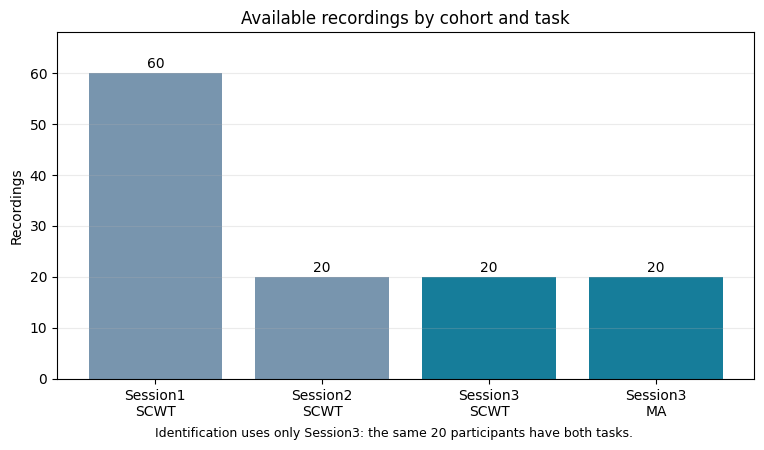

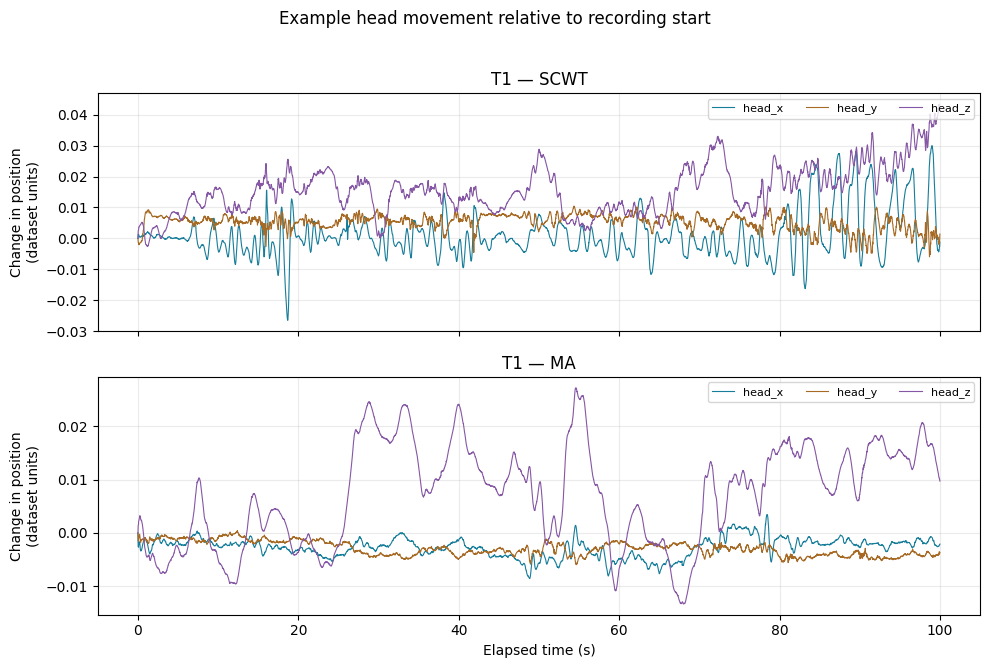

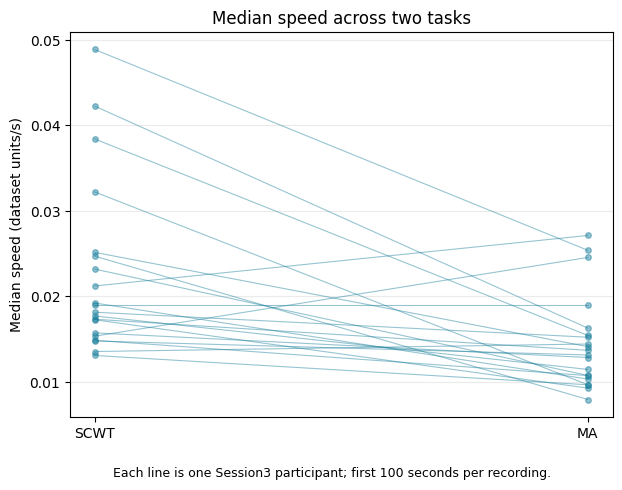

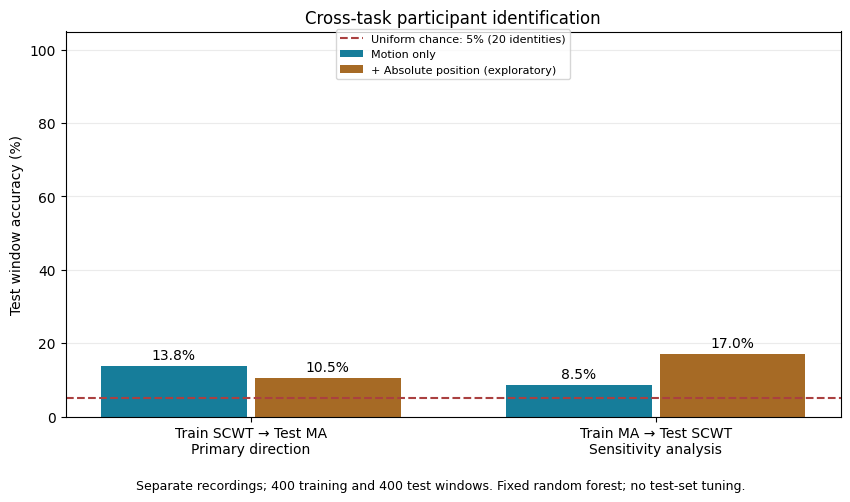

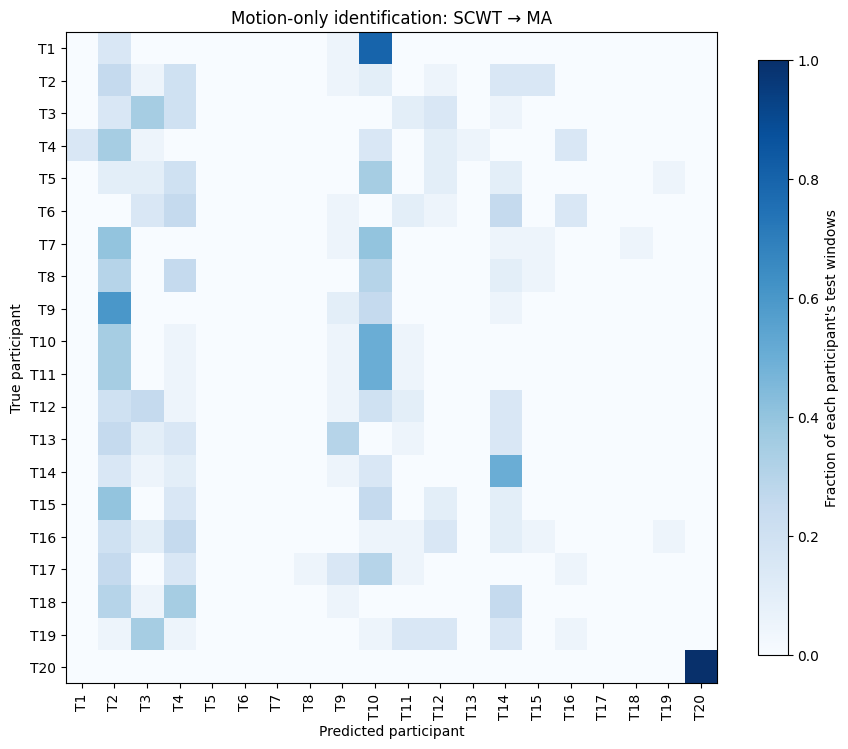

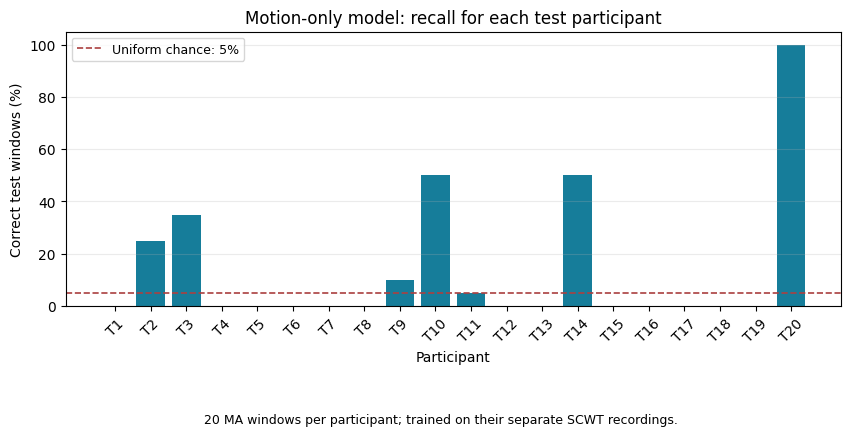

In [ ]:
GRAPH_DIR = OUTPUT_DIR / "preliminary_graphs"
GRAPH_DIR.mkdir(parents=True, exist_ok=True)
def save_graph(fig, name):
    fig.savefig(GRAPH_DIR / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    fig.savefig(GRAPH_DIR / f"{name}.pdf", bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

# Graph 1: recording coverage (all available head-movement data).
counts = df[["session", "task", "recording_file"]].drop_duplicates().groupby(["session", "task"], observed=True).size()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar([f"{s}\n{t}" for s, t in counts.index], counts.values, color=["#7895ae", "#7895ae", "#167d9a", "#167d9a"])
for i, n in enumerate(counts.values):
    ax.text(i, n + 1, str(n), ha="center")
ax.set(title="Available recordings by cohort and task", ylabel="Recordings", ylim=(0, 68))
ax.grid(axis="x", visible=False)
fig.text(.5, -.02, "Identification uses only Session3: the same 20 participants have both tasks.", ha="center", fontsize=9)
save_graph(fig, "01_dataset_coverage")

# Graph 2: example traces for both tasks of one participant, at most 100 seconds.
fig, axes = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
for ax, task in zip(axes, ["SCWT", "MA"]):
    example = paired.loc[paired["participant_id"].astype(str).eq("T1") & paired["task"].astype(str).eq(task)
                         & paired["elapsed_seconds"].lt(100)].sort_values("sample_index")
    for coordinate, color in zip(["head_x", "head_y", "head_z"], ["#167d9a", "#a66a25", "#8657a5"]):
        centered = example[coordinate] - example[coordinate].iloc[0]
        ax.plot(example["elapsed_seconds"], centered, label=coordinate, color=color, linewidth=.8)
    ax.set(title=f"T1 — {task}", ylabel="Change in position\n(dataset units)")
    ax.legend(loc="upper right", ncol=3, fontsize=8)
axes[-1].set_xlabel("Elapsed time (s)")
fig.suptitle("Example head movement relative to recording start", y=1.02)
fig.tight_layout()
save_graph(fig, "02_example_head_movement")

# Graph 3: one within-recording median per participant/task (descriptive).
participant_speed = paired.loc[paired["elapsed_seconds"].lt(100) & paired["quality_flag"].isna()
                               & np.isfinite(paired["speed"])].groupby(["participant_id", "task"], observed=True)["speed"].median().unstack()
fig, ax = plt.subplots(figsize=(7, 5))
for _, row in participant_speed.iterrows():
    ax.plot([0, 1], row[["SCWT", "MA"]], "o-", color="#167d9a", alpha=.45, markersize=4, linewidth=.8)
ax.set_xticks([0, 1], ["SCWT", "MA"])
ax.set(title="Median speed across two tasks", ylabel="Median speed (dataset units/s)")
ax.grid(axis="x", visible=False)
fig.text(.5, -.01, "Each line is one Session3 participant; first 100 seconds per recording.", ha="center", fontsize=9)
participant_speed.to_csv(ID_OUTPUT / "participant_task_median_speed.csv")
save_graph(fig, "03_paired_task_speed")

# Graph 4: report all prespecified evaluations, including weak results.
fig, ax = plt.subplots(figsize=(10, 5))
directions = ["SCWT → MA", "MA → SCWT"]
x = np.arange(len(directions))
for offset, (feature_name, color, label) in zip([-.19, .19], [
    ("Motion only (primary)", "#167d9a", "Motion only"),
    ("Motion + absolute position (exploratory)", "#a66a25", "+ Absolute position (exploratory)")
]):
    values = metrics.loc[metrics["feature_set"].eq(feature_name)].set_index("direction").loc[directions, "accuracy"].to_numpy() * 100
    bars = ax.bar(x + offset, values, width=.36, color=color, label=label)
    ax.bar_label(bars, labels=[f"{v:.1f}%" for v in values], padding=3, fontsize=10)
ax.axhline(5, color="#aa4040", linestyle="--", linewidth=1.5, label="Uniform chance: 5% (20 identities)")
ax.set_xticks(x, ["Train SCWT → Test MA\nPrimary direction", "Train MA → Test SCWT\nSensitivity analysis"])
ax.set(title="Cross-task participant identification", ylabel="Test window accuracy (%)", ylim=(0, 105))
ax.legend(loc="upper center", bbox_to_anchor=(.5, 1.02), fontsize=8)
ax.grid(axis="x", visible=False)
fig.text(.5, -.035, "Separate recordings; 400 training and 400 test windows. Fixed random forest; no test-set tuning.", ha="center", fontsize=9)
save_graph(fig, "04_identification_accuracy")

# Graph 5: primary model's true-row-normalized confusion matrix.
rates = primary_confusion / primary_confusion.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(9, 8))
image = ax.imshow(rates, vmin=0, vmax=1, cmap="Blues", aspect="equal")
ax.set_xticks(range(20), EXPECTED_IDS, rotation=90)
ax.set_yticks(range(20), EXPECTED_IDS)
ax.set(title="Motion-only identification: SCWT → MA", xlabel="Predicted participant", ylabel="True participant")
ax.grid(False)
fig.colorbar(image, ax=ax, label="Fraction of each participant's test windows", shrink=.8)
fig.tight_layout()
save_graph(fig, "05_primary_confusion_matrix")

# Graph 6: person-level spread, not just a pooled score.
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(EXPECTED_IDS, per_person["recall"] * 100, color="#167d9a")
ax.axhline(5, color="#aa4040", linestyle="--", linewidth=1.2, label="Uniform chance: 5%")
ax.set(title="Motion-only model: recall for each test participant", xlabel="Participant", ylabel="Correct test windows (%)", ylim=(0, 105))
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
ax.legend(fontsize=9)
fig.subplots_adjust(bottom=.27)
fig.text(.5, .01, "20 MA windows per participant; trained on their separate SCWT recordings.", ha="center", fontsize=9)
save_graph(fig, "06_per_participant_recall")

## 10. Save results and interpretation

This cell exports a plain-language summary and a reproducibility manifest (including the input file hash, package versions, features, and fixed configuration), then bundles the tables and figures into a ZIP.

**Limits to discuss in the report:** 20 people; two tasks in one acquisition session; correlated windows; no independent day/device replication; noisy finite-difference derivatives; head position only; no evidence about unseen identities. This analysis does not use the provisional stress-phase labels as predictors.

In [ ]:
import hashlib, json, platform, shutil
primary_result = metrics.loc[metrics["direction"].eq("SCWT → MA")
                            & metrics["feature_set"].eq("Motion only (primary)")].iloc[0]
summary_text = f"""PRELIMINARY RESULTS — ECE 535 — 2026-11-17

Question: Can head-movement features identify one of 20 enrolled participants across two tasks?
Primary evaluation: train on Session3 SCWT recordings; test on separate Session3 MA recordings.
Each recording contributes its first 100 seconds as twenty non-overlapping 5-second windows.
Training: 20 recordings / 400 windows. Testing: 20 different recordings / 400 windows.
Model: random forest, 300 trees, minimum leaf size 2, seed 535. No test-set parameter search.
Predictors: 18 translation-invariant summaries of head position variability, speed, and acceleration.

Primary accuracy: {primary_result['accuracy']:.2%}
Primary balanced accuracy: {primary_result['balanced_accuracy']:.2%}
Primary macro-F1: {primary_result['macro_f1']:.4f}
Uniform chance accuracy: {primary_result['uniform_chance']:.2%}
Participants with at least one correctly identified test window: {int(per_person['correct_windows'].gt(0).sum())}/20
Correct test windows: {int(primary_predictions['correct'].sum())}/{len(primary_predictions)}; success varies substantially by person.

Interpretation: This is a small, closed-set cross-task experiment on 20 known participants.
It does not establish cross-day, cross-device, or unseen-person identification.
Windows within each recording are correlated; 400 windows are not 400 independent people.
No window-level confidence interval or significance claim is made.
Absolute-position results are exploratory and may reflect pose, placement, or environment.
Other cohorts have one recording per identity and are excluded from this separate-recording test.
The source study concerns stress assessment; this identification experiment is a new project baseline,
not a reproduction of published identification results. Phase labels are not predictors.
Body/eye/hand signals are not included. Compare modalities only with a compatible evaluation protocol.
"""
print(summary_text)
(ID_OUTPUT / "preliminary_results.txt").write_text(summary_text)
digest = hashlib.sha256()
with open(DATA_PATH, "rb") as source:
    for chunk in iter(lambda: source.read(1024 * 1024), b""):
        digest.update(chunk)
manifest = dict(seed=SEED, window_seconds=WINDOW_SECONDS, seconds_per_recording=SECONDS_PER_RECORDING,
                cohort="Session3", participants=EXPECTED_IDS, primary_direction="SCWT → MA",
                data_filename=Path(DATA_PATH).name, data_sha256=digest.hexdigest(),
                python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
                scikit_learn=sklearn.__version__, feature_sets=feature_sets,
                protocol="Fixed model; separate recording/task holdout; same enrolled identities; no hyperparameter tuning")
(ID_OUTPUT / "run_manifest.json").write_text(json.dumps(manifest, indent=2))
archive = shutil.make_archive("ece535_preliminary_results", "zip", OUTPUT_DIR)
print(f"All tables and PNG/PDF figures: {Path(archive).resolve()}")

PRELIMINARY RESULTS — ECE 535 — 2026-11-17

Question: Can head-movement features identify one of 20 enrolled participants across two tasks?
Primary evaluation: train on Session3 SCWT recordings; test on separate Session3 MA recordings.
Each recording contributes its first 100 seconds as twenty non-overlapping 5-second windows.
Training: 20 recordings / 400 windows. Testing: 20 different recordings / 400 windows.
Model: random forest, 300 trees, minimum leaf size 2, seed 535. No test-set parameter search.
Predictors: 18 translation-invariant summaries of head position variability, speed, and acceleration.

Primary accuracy: 13.75%
Primary balanced accuracy: 13.75%
Primary macro-F1: 0.1009
Uniform chance accuracy: 5.00%
Participants with at least one correctly identified test window: 7/20
Correct test windows: 55/400; success varies substantially by person.

Interpretation: This is a small, closed-set cross-task experiment on 20 known participants.
It does not establish cross-day, cross-

## Report checklist

- Explain the separate-recording, cross-task evaluation and its 5% chance baseline.
- Include the primary motion-only accuracy, macro-F1, confusion matrix, and per-participant differences.
- Report the reverse direction and absolute-position comparison as exploratory sensitivity analyses.
- Describe the dataset, features, quality filtering, and fixed model settings; cite the original dataset paper.
- Discuss privacy implications only within this small enrolled cohort, plus limitations and next experiments.
- Agree on compatible protocols with the gaze/gesture team before comparing scores.

**Dataset citation:** Ferrarotti, Baldoni, Carli & Battisti (2024), *Stress Assessment for Augmented Reality Applications Based on Head Movement Features*. DOI: [10.1109/TVCG.2024.3385637](https://doi.org/10.1109/TVCG.2024.3385637).

## 11. Add full-body motion: UTD-MHAD

**You can start here without running the head-study cells above.** This section has its own imports, data download, features, experiments, and results. It preserves the original Roma Tre experiment as a separate study.

UTD-MHAD contains **20-joint skeletons** covering the head, trunk, arms, hands, hips, legs, and feet. Eight participants performed 27 actions four times; the authors removed three corrupted trials, leaving 861 recordings. We download only the approximately 14 MiB skeleton ZIP. RGB videos, depth images, and wearable-sensor files are separate modalities and are not needed here.

This is a practical laboratory Kinect dataset, rather than headset-based capture. It extends this project's movement/privacy question to full-body skeletons, but is not a replication of the head study or proof about deployed MR systems.

**Access and citation:** [official UTD-MHAD page](https://personal.utdallas.edu/~kehtar/UTD-MHAD.html) · [official skeleton archive](https://personal.utdallas.edu/~kehtar/UTD-MAD/Skeleton.zip). The authors describe a public-domain research release in their [original paper](https://jafari.tamu.edu/wp-content/uploads/2019/06/ICIP2015-Chen-Final.pdf); the landing page does not assign a named CC license. Cite Chen, Jafari & Kehtarnavaz, *UTD-MHAD: A Multimodal Dataset for Human Action Recognition Utilizing a Depth Camera and a Wearable Inertial Sensor*, ICIP 2015.

The loader checks the archive's SHA-256 hash and all recording shapes, finite values, zero-joint frames and torso scales. It preserves the official joint-order document. The archive's joint order differs from the Kinect SDK order: **head is joint 1 and pelvis is joint 4** (one-based).

In [1]:
from pathlib import Path
from io import BytesIO
from zipfile import ZipFile
from urllib.request import urlopen, Request
import hashlib, json, platform, re, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from IPython.display import display, Image

BODY_ROOT = Path("utd_mhad")
BODY_OUTPUT = Path("full_body_outputs")
BODY_GRAPHS = BODY_OUTPUT / "graphs"
BODY_ROOT.mkdir(exist_ok=True)
BODY_GRAPHS.mkdir(parents=True, exist_ok=True)
UTD_SOURCE = "https://personal.utdallas.edu/~kehtar/UTD-MAD/Skeleton.zip"
UTD_SHA256 = "f029ea1d4e4c330b2c61307b6d532b34c3920bcac1f4c22c7827f406e2c7ac00"
archive_path = BODY_ROOT / "Skeleton.zip"
if not archive_path.exists():
    print("Downloading the official skeleton-only archive (about 14 MiB)...")
    request = Request(UTD_SOURCE, headers={"User-Agent": "Python educational dataset loader"})
    with urlopen(request, timeout=120) as response, archive_path.open("wb") as output:
        shutil.copyfileobj(response, output)
actual_hash = hashlib.sha256(archive_path.read_bytes()).hexdigest()
if actual_hash != UTD_SHA256:
    raise ValueError("Archive hash differs from the verified release. Recheck the official source before proceeding.")

JOINT_NAMES = ["head", "shoulder_center", "spine", "hip_center", "left_shoulder",
               "left_elbow", "left_wrist", "left_hand", "right_shoulder", "right_elbow",
               "right_wrist", "right_hand", "left_hip", "left_knee", "left_ankle", "left_foot",
               "right_hip", "right_knee", "right_ankle", "right_foot"]
# Author's joint-order file and show_joint_3D.m, converted to zero-based indexing.
BONES = [(a-1, b-1) for a, b in [(1,2),(2,3),(3,4),(2,5),(5,6),(6,7),(7,8),
                                (2,9),(9,10),(10,11),(11,12),(4,13),(13,14),
                                (14,15),(15,16),(4,17),(17,18),(18,19),(19,20)]]
ACTION_NAMES = ["Swipe left", "Swipe right", "Wave", "Clap", "Throw", "Arm cross", "Basketball shoot",
                "Draw X", "Draw circle clockwise", "Draw circle counterclockwise", "Draw triangle",
                "Bowling", "Boxing", "Baseball swing", "Tennis swing", "Arm curl", "Tennis serve",
                "Push", "Knock", "Catch", "Pick up and throw", "Jog", "Walk", "Sit to stand",
                "Stand to sit", "Lunge", "Squat"]
body_recordings, body_audit = [], []
with ZipFile(archive_path) as package:
    joint_order_files = [name for name in package.namelist() if name.endswith("Skeleton_joint_order.txt")]
    assert len(joint_order_files) == 1
    (BODY_OUTPUT / "official_joint_order.txt").write_bytes(package.read(joint_order_files[0]))
    for member in sorted(package.namelist()):
        match = re.search(r"(?:^|/)a(\d+)_s(\d+)_t(\d+)_skeleton\.mat$", member)
        if not match:
            continue
        action, subject, trial = map(int, match.groups())
        skeleton = np.asarray(loadmat(BytesIO(package.read(member)))["d_skel"], dtype=float)
        valid = skeleton.ndim == 3 and skeleton.shape[:2] == (20,3) and skeleton.shape[2] >= 10
        finite = bool(np.isfinite(skeleton).all())
        zero_frames = int(np.any(np.all(skeleton == 0, axis=1), axis=0).sum()) if valid else -1
        torso_lengths = np.linalg.norm(skeleton[1] - skeleton[3], axis=0) if valid else np.array([0.])
        scale = float(np.median(torso_lengths))
        retained = valid and finite and zero_frames == 0 and scale > 1e-8
        audit = dict(file_id=Path(member).name, action_id=action, action=ACTION_NAMES[action-1],
                     subject_id=f"S{subject}", trial=trial, frames=skeleton.shape[-1],
                     finite=finite, zero_joint_frames=zero_frames, torso_scale_dataset_units=scale,
                     retained=retained)
        body_audit.append(audit)
        if retained:
            body_recordings.append(dict(**audit, skeleton=skeleton))
body_manifest = pd.DataFrame(body_audit)
assert len(body_manifest) == 861 and body_manifest["retained"].all()
assert set(body_manifest["subject_id"]) == {f"S{i}" for i in range(1,9)}
assert body_manifest["file_id"].is_unique
body_manifest.to_csv(BODY_OUTPUT / "recording_manifest.csv", index=False)
print(f"Verified {len(body_recordings)} recordings, 8 participants, 27 actions, 20 joints.")
print(f"Total frames: {body_manifest['frames'].sum():,}; frames per recording: {body_manifest['frames'].min()}–{body_manifest['frames'].max()}.")
print("One recording will produce one feature row and one test prediction; frames are never randomly split.")
display(pd.crosstab(body_manifest["subject_id"], body_manifest["trial"]))

Verified 861 recordings, 8 participants, 27 actions, 20 joints.
Total frames: 58,299; frames per recording: 41–125.
One recording will produce one feature row and one test prediction; frames are never randomly split.


trial,1,2,3,4
subject_id,,,,
S1,27,27,27,26
S2,27,27,27,27
S3,27,27,27,27
S4,27,27,27,27
S5,27,27,27,27
S6,27,27,27,26
S7,27,27,27,27
S8,27,27,27,26


## 12. See the full body move

The following snapshots and animation reconstruct a participant's squat directly from the 20 joint coordinates. The skeleton includes arms, trunk and both legs. Positions are displayed relative to the pelvis in the **first frame**, so vertical movement remains visible, and divided by the median torso length for readable units.

The visualization uses the authors' skeleton edges. The documented nominal capture rate is approximately 30 fps; this is not a guarantee of precise timestamps for every frame. No photographs are needed to draw the skeleton.

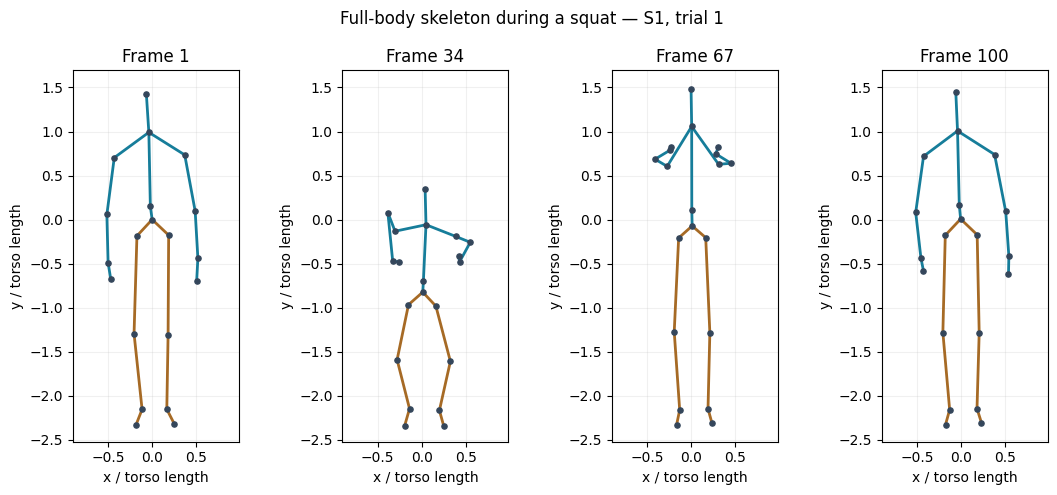

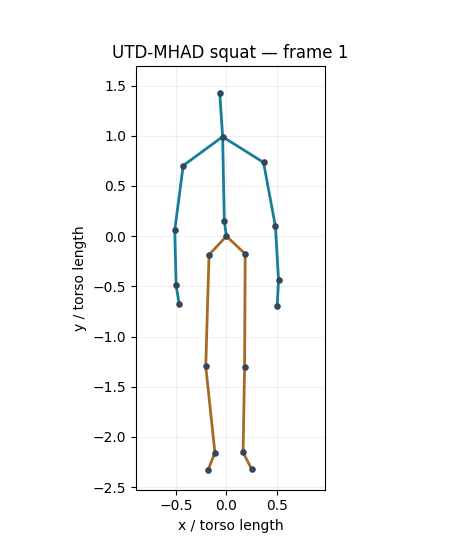

Skeleton reconstructed from joint coordinates. Playback uses the documented nominal ~30 fps.


In [2]:
from matplotlib.animation import FuncAnimation, PillowWriter

example_body = next(r for r in body_recordings if r["action_id"] == 27 and r["subject_id"] == "S1" and r["trial"] == 1)
raw_pose = example_body["skeleton"]
# Visualization keeps vertical/root travel visible. Model features below use a different,
# per-frame pelvis centering to remove absolute recording position.
visible_pose = (raw_pose - raw_pose[3,:,0][None,:,None]) / example_body["torso_scale_dataset_units"]
lim = [float(visible_pose[:,k,:].min())-.15 for k in (0,1)] + [float(visible_pose[:,k,:].max())+.15 for k in (0,1)]

def draw_body_frame(ax, frame, title):
    pose = visible_pose[:,:,frame]
    for a, b in BONES:
        color = "#a66a25" if a >= 12 or b >= 12 else "#167d9a"
        ax.plot(pose[[a,b],0], pose[[a,b],1], color=color, linewidth=2)
    ax.scatter(pose[:,0], pose[:,1], s=14, color="#34465b", zorder=3)
    ax.set(xlim=(lim[0],lim[2]), ylim=(lim[1],lim[3]), title=title,
           xlabel="x / torso length", ylabel="y / torso length")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=.18)

frames = np.linspace(0, raw_pose.shape[2]-1, 4).round().astype(int)
fig, axes = plt.subplots(1,4,figsize=(11,5))
for ax, frame in zip(axes,frames):
    draw_body_frame(ax,int(frame),f"Frame {frame+1}")
fig.suptitle("Full-body skeleton during a squat — S1, trial 1")
fig.tight_layout()
for extension in ["png","pdf"]:
    fig.savefig(BODY_GRAPHS / f"01_full_body_pose_sequence.{extension}",dpi=170,bbox_inches="tight")
plt.show()
plt.close(fig)

fig, ax = plt.subplots(figsize=(4.5,5.5))
def animate_body(frame):
    ax.clear()
    draw_body_frame(ax,int(frame),f"UTD-MHAD squat — frame {frame+1}")
    return []
animation = FuncAnimation(fig,animate_body,frames=range(0,raw_pose.shape[2],2),interval=1000*2/30)
animation.save(BODY_GRAPHS / "full_body_squat.gif",writer=PillowWriter(fps=15),dpi=100)
plt.close(fig)
display(Image(filename=str(BODY_GRAPHS / "full_body_squat.gif")))
print("Skeleton reconstructed from joint coordinates. Playback uses the documented nominal ~30 fps.")

## 13. Make comparable head and full-body features

**One complete action recording becomes one example.** For the model, center each frame on the pelvis, then divide by that recording's median shoulder-center-to-pelvis distance. This removes absolute camera position and overall torso scale, but does not remove orientation, relative limb proportions or all capture context.

Three fixed feature sets use the same recordings:

1. **Head relative to pelvis:** 17 summaries of the head's relative position and frame-to-frame change.
2. **Full body pose + movement:** the same 17 summaries for each of the 19 non-pelvis joints (323 predictors).
3. **Full body movement only:** frame-to-frame change summaries for those joints (95 predictors), excluding static pose means and position variability summaries.

Position summaries are mean, standard deviation, interquartile range and range for each coordinate. Dynamic summaries are median/90th-percentile step length and coordinate-wise step standard deviations. We use changes **per frame**, avoiding unsupported claims about coordinate units or exact sampling intervals.

These are comparisons of available information, with different feature dimensions; they are not capacity-matched proofs of sensor superiority. No participant labels, action IDs, trial numbers, file names or recording lengths are predictors.

In [3]:
body_feature_rows = []
for recording in body_recordings:
    skeleton = recording["skeleton"]
    # Center every frame on the pelvis; scale each recording by median torso length.
    # This is a deterministic within-recording transform, not fitted across train/test.
    normalized = (skeleton - skeleton[3:4,:,:]) / recording["torso_scale_dataset_units"]
    assert np.allclose(normalized[3],0)
    row = {key:recording[key] for key in ["file_id","subject_id","action_id","trial"]}
    for j, joint in enumerate(JOINT_NAMES):
        if j == 3:
            continue  # Pelvis is the zero origin, so its features carry no information.
        position = normalized[j]
        for axis, values in zip("xyz",position):
            for statistic, value in {
                "mean":values.mean(), "std":values.std(ddof=0),
                "iqr":np.quantile(values,.75)-np.quantile(values,.25),
                "range":np.ptp(values),
            }.items():
                row[f"pose__{joint}__{axis}_{statistic}"] = float(value)
        steps = np.diff(position,axis=1)
        step_length = np.linalg.norm(steps,axis=0)
        row[f"dynamic__{joint}__step_median"] = float(np.median(step_length))
        row[f"dynamic__{joint}__step_p90"] = float(np.quantile(step_length,.90))
        for axis,values in zip("xyz",steps):
            row[f"dynamic__{joint}__{axis}_step_std"] = float(values.std(ddof=0))
    body_feature_rows.append(row)
body_features = pd.DataFrame(body_feature_rows)
body_metadata = ["file_id","subject_id","action_id","trial"]
body_head_features = [c for c in body_features if c.startswith(("pose__head__","dynamic__head__"))]
body_full_features = [c for c in body_features if c not in body_metadata]
body_dynamic_features = [c for c in body_full_features if c.startswith("dynamic__")]
body_feature_sets = {
    "Head relative to pelvis":body_head_features,
    "Full body pose + movement":body_full_features,
    "Full body movement only":body_dynamic_features,
}
assert len(body_head_features)==17 and len(body_full_features)==323 and len(body_dynamic_features)==95
assert not set(body_metadata)&set(body_full_features)
assert np.isfinite(body_features[body_full_features].to_numpy()).all()
body_features.to_csv(BODY_OUTPUT / "full_body_recording_features.csv",index=False)
print("Feature counts:", {name:len(values) for name,values in body_feature_sets.items()})
print("One row per entire action recording. No labels, action/trial IDs, filenames, or frame counts are predictors.")
print("Movement features measure change per frame; exact per-frame timestamps/metric coordinate units are not assumed.")
display(body_features[body_metadata].head())

Feature counts: {'Head relative to pelvis': 17, 'Full body pose + movement': 323, 'Full body movement only': 95}
One row per entire action recording. No labels, action/trial IDs, filenames, or frame counts are predictors.
Movement features measure change per frame; exact per-frame timestamps/metric coordinate units are not assumed.


,file_id,subject_id,action_id,trial
0,a10_s1_t1_skeleton.mat,S1,10,1
1,a10_s1_t2_skeleton.mat,S1,10,2
2,a10_s1_t3_skeleton.mat,S1,10,3
3,a10_s1_t4_skeleton.mat,S1,10,4
4,a10_s2_t1_skeleton.mat,S2,10,1


## 14. Identify participants from separate full-body recordings

The target is **which of eight enrolled participants** produced a recording. Their labels S1–S8 are pseudonyms. This is a new identification experiment, distinct from the dataset authors' action-recognition task.

- **Primary:** train on trials 1–3 and test on complete trial-4 recordings, across all 27 actions. There are 648 training and 213 test recordings; three trial-4 files are absent in the release. The test actions have been seen during training, but the recordings have not.
- **Exploratory:** train on actions 1–21 and test on actions 22–27, keeping the same identities. This transfers from an upper-body-heavy action group to a lower-body-heavy group. There are 671 training and 190 test recordings. This reuses the dataset and is not independent replication.
- Fit a fixed random forest (300 trees, minimum leaf size 2, square-root feature selection, balanced subsampling, seed 535). There is no test-set parameter search.
- Compare all feature sets on exactly the same partition. Score **whole recordings**, with balanced accuracy, raw accuracy and macro-F1. Eight-class uniform chance is **12.5%**.

Recordings are kept intact. Separate trials do not establish separation by day/session or robustness to a new camera. The three missing files create slight class imbalance, which is why balanced accuracy is emphasized.

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix
import sklearn

BODY_LABELS = [f"S{i}" for i in range(1,9)]
BODY_SEED = 535
body_protocols = {
    "Held-out trial 4 (primary)":(body_features["trial"].isin([1,2,3]),body_features["trial"].eq(4)),
    "Held-out actions 22–27 (exploratory)":(body_features["action_id"].le(21),body_features["action_id"].ge(22)),
}
body_metric_rows, body_prediction_frames, body_split_rows = [], [], []
for protocol,(train_mask,test_mask) in body_protocols.items():
    train,test = body_features.loc[train_mask],body_features.loc[test_mask]
    assert set(train.file_id).isdisjoint(set(test.file_id))
    assert set(train.subject_id)==set(test.subject_id)==set(BODY_LABELS)
    if protocol.startswith("Held-out actions"):
        assert set(train.action_id).isdisjoint(set(test.action_id))
    for partition,part in [("train",train),("test",test)]:
        for _,record in part[body_metadata].iterrows():
            body_split_rows.append(dict(protocol=protocol,partition=partition,**record.to_dict()))
    for feature_name,predictors in body_feature_sets.items():
        model = make_pipeline(SimpleImputer(strategy="median"),
            RandomForestClassifier(n_estimators=300,min_samples_leaf=2,max_features="sqrt",
                class_weight="balanced_subsample",random_state=BODY_SEED,n_jobs=-1))
        model.fit(train[predictors],train.subject_id)
        predicted = model.predict(test[predictors])
        body_metric_rows.append(dict(protocol=protocol,feature_set=feature_name,
            participants=8,train_recordings=len(train),test_recordings=len(test),
            accuracy=accuracy_score(test.subject_id,predicted),
            balanced_accuracy=balanced_accuracy_score(test.subject_id,predicted),
            macro_f1=f1_score(test.subject_id,predicted,average="macro",zero_division=0),uniform_chance=.125))
        predictions = test[body_metadata].copy()
        predictions["predicted_id"]=predicted
        predictions["correct"]=predictions.subject_id.eq(predictions.predicted_id)
        predictions["protocol"],predictions["feature_set"]=protocol,feature_name
        body_prediction_frames.append(predictions)
body_metrics = pd.DataFrame(body_metric_rows)
body_predictions = pd.concat(body_prediction_frames,ignore_index=True)
body_metrics.to_csv(BODY_OUTPUT / "identification_metrics.csv",index=False)
body_predictions.to_csv(BODY_OUTPUT / "test_predictions.csv",index=False)
pd.DataFrame(body_split_rows).to_csv(BODY_OUTPUT / "split_manifest.csv",index=False)
display(body_metrics[["protocol","feature_set","train_recordings","test_recordings","accuracy","balanced_accuracy","macro_f1"]].round(4))
print("Chance is 12.5% among eight enrolled identities; these are whole-recording scores.")
print("No frame/window from a test recording is in training. Fixed settings; no tuning on either test set.")

,protocol,feature_set,train_recordings,test_recordings,accuracy,balanced_accuracy,macro_f1
0,Held-out trial 4 (primary),Head relative to pelvis,648,213,0.7746,0.7749,0.7771
1,Held-out trial 4 (primary),Full body pose + movement,648,213,1.0000,1.0000,1.0000
2,Held-out trial 4 (primary),Full body movement only,648,213,0.9296,0.9291,0.9302
3,Held-out actions 22–27 (exploratory),Head relative to pelvis,671,190,0.2158,0.2149,0.1808
4,Held-out actions 22–27 (exploratory),Full body pose + movement,671,190,0.4421,0.4438,0.4388
5,Held-out actions 22–27 (exploratory),Full body movement only,671,190,0.1684,0.1714,0.1158


Chance is 12.5% among eight enrolled identities; these are whole-recording scores.
No frame/window from a test recording is in training. Fixed settings; no tuning on either test set.


### Diagnostic: body proportions and duplicates

The unexpectedly high separate-trial result motivated this **post-hoc diagnostic**, which did not alter or tune the primary model. We check whether any entire numerical recordings are duplicated, then train the same fixed classifier using only median relative bone lengths (19 skeleton edges divided by torso length).

These features summarize relative body dimensions and tracking geometry rather than a temporal movement pattern. If they also identify participants well, the main score cannot be attributed solely to a distinctive movement style. This is an explanatory check on the existing test set, not independent confirmatory evidence.

In [5]:
# Post-hoc diagnostic prompted by the high primary score; it did not select/tune the primary model.
# Check complete numerical sequences for duplicates across the whole archive.
recording_hashes=[hashlib.sha256(r["skeleton"].tobytes()).hexdigest() for r in body_recordings]
assert len(set(recording_hashes))==len(recording_hashes), "Duplicate numerical recordings need investigation."
bone_rows=[]
for recording in body_recordings:
    skeleton=recording["skeleton"]
    bone_rows.append({f"bone_{i+1}_{JOINT_NAMES[a]}_to_{JOINT_NAMES[b]}":
        float(np.median(np.linalg.norm(skeleton[a]-skeleton[b],axis=0))/recording["torso_scale_dataset_units"])
        for i,(a,b) in enumerate(BONES)})
bone_features=pd.DataFrame(bone_rows)
bone_train=body_features.trial.lt(4)
bone_test=body_features.trial.eq(4)
bone_model=RandomForestClassifier(n_estimators=300,min_samples_leaf=2,max_features="sqrt",
    class_weight="balanced_subsample",random_state=535,n_jobs=-1)
bone_model.fit(bone_features.loc[bone_train],body_features.loc[bone_train,"subject_id"])
bone_predictions=bone_model.predict(bone_features.loc[bone_test])
bone_balanced=balanced_accuracy_score(body_features.loc[bone_test,"subject_id"],bone_predictions)
bone_features.join(body_features[body_metadata]).to_csv(BODY_OUTPUT / "relative_bone_length_features.csv",index=False)
body_diagnostic=dict(label="Post-hoc relative-bone-length diagnostic",balanced_accuracy=bone_balanced,
    unique_numerical_recordings=len(set(recording_hashes)),total_recordings=len(recording_hashes),
    interpretation="Relative bone lengths alone carry identity-related information in this dataset; full-body pose/movement accuracy cannot be attributed solely to movement style.")
(BODY_OUTPUT / "body_proportion_diagnostic.json").write_text(json.dumps(body_diagnostic,indent=2))
print(f"Unique numerical sequences: {len(set(recording_hashes))}/{len(recording_hashes)}.")
print(f"Relative-bone-length-only diagnostic balanced accuracy: {bone_balanced:.2%}.")
print(body_diagnostic["interpretation"])

Unique numerical sequences: 861/861.
Relative-bone-length-only diagnostic balanced accuracy: 93.02%.
Relative bone lengths alone carry identity-related information in this dataset; full-body pose/movement accuracy cannot be attributed solely to movement style.


## 15. Full-body result figures

The accuracy chart compares head-relative, full-body pose/movement, and movement-only information within UTD-MHAD. The confusion matrix reports the primary full-body pose/movement condition; each cell also shows the number of recordings.

**Do not compare these percentages directly with the earlier Roma Tre percentage:** UTD uses eight people and recording-level predictions, while Roma Tre uses 20 different people and five-second-window predictions. They also differ in task, sensor and collection setting.

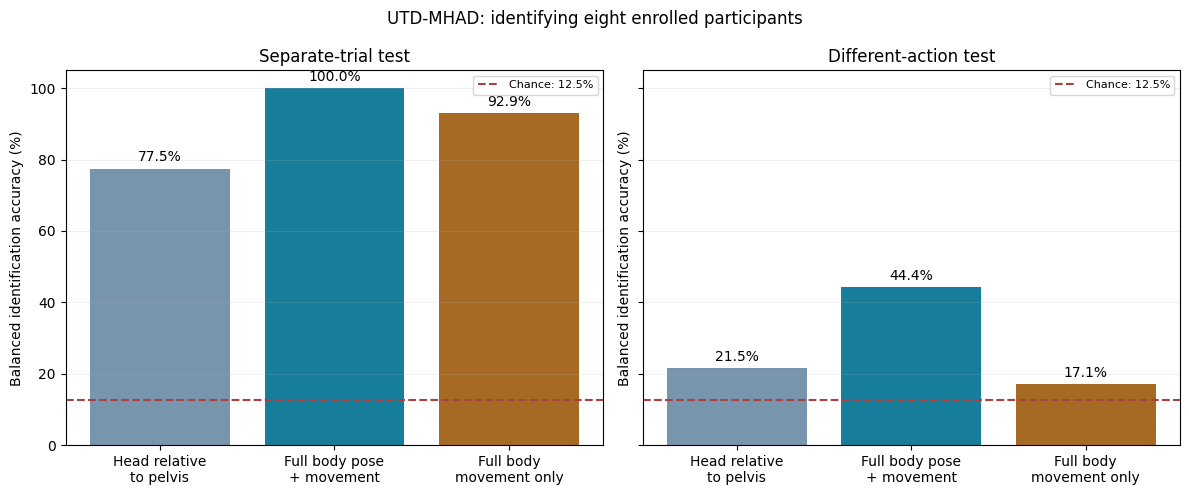

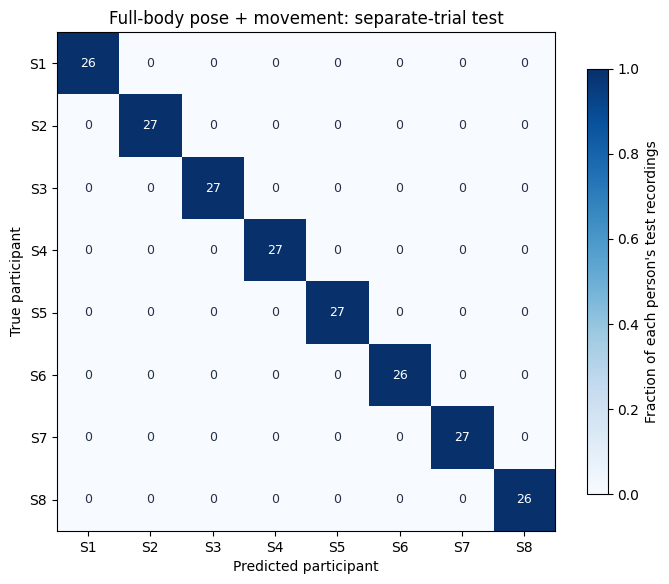

In [6]:
def body_save_figure(fig,name):
    for extension in ["png","pdf"]:
        fig.savefig(BODY_GRAPHS / f"{name}.{extension}",dpi=170,bbox_inches="tight",facecolor="white")
    plt.show()
    plt.close(fig)

fig,axes = plt.subplots(1,2,figsize=(12,5),sharey=True)
body_colors = ["#7895ae","#167d9a","#a66a25"]
short_names = ["Head relative\nto pelvis","Full body pose\n+ movement","Full body\nmovement only"]
for ax,(protocol,_) in zip(axes,body_protocols.items()):
    subset=body_metrics.loc[body_metrics.protocol.eq(protocol)].set_index("feature_set").loc[list(body_feature_sets)]
    values=subset.balanced_accuracy.to_numpy()*100
    bars=ax.bar(range(3),values,color=body_colors)
    ax.bar_label(bars,labels=[f"{v:.1f}%" for v in values],padding=3)
    ax.axhline(12.5,color="#aa4040",linestyle="--",label="Chance: 12.5%")
    ax.set_xticks(range(3),short_names)
    ax.set(title="Separate-trial test" if protocol.startswith("Held-out trial") else "Different-action test",ylim=(0,105))
    ax.set_ylabel("Balanced identification accuracy (%)")
    ax.grid(axis="y",alpha=.2)
    ax.legend(loc="upper right",fontsize=8)
fig.suptitle("UTD-MHAD: identifying eight enrolled participants")
fig.tight_layout()
body_save_figure(fig,"02_full_body_identification_accuracy")

selected=body_predictions.loc[body_predictions.protocol.eq("Held-out trial 4 (primary)")
                             & body_predictions.feature_set.eq("Full body pose + movement")]
cm=confusion_matrix(selected.subject_id,selected.predicted_id,labels=BODY_LABELS)
pd.DataFrame(cm,index=BODY_LABELS,columns=BODY_LABELS).to_csv(BODY_OUTPUT / "primary_full_body_confusion.csv")
rates=cm/cm.sum(axis=1,keepdims=True)
fig,ax=plt.subplots(figsize=(7,6))
image=ax.imshow(rates,vmin=0,vmax=1,cmap="Blues")
for i in range(8):
    for j in range(8):
        ax.text(j,i,str(cm[i,j]),ha="center",va="center",color="white" if rates[i,j]>.5 else "#253044",fontsize=9)
ax.set_xticks(range(8),BODY_LABELS)
ax.set_yticks(range(8),BODY_LABELS)
ax.set(title="Full-body pose + movement: separate-trial test",xlabel="Predicted participant",ylabel="True participant")
fig.colorbar(image,ax=ax,label="Fraction of each person's test recordings",shrink=.8)
fig.tight_layout()
body_save_figure(fig,"03_full_body_confusion_matrix")
per_person=selected.groupby("subject_id").correct.agg(["sum","count","mean"]).reindex(BODY_LABELS)
per_person.columns=["correct_recordings","test_recordings","recall"]
per_person.to_csv(BODY_OUTPUT / "primary_full_body_per_participant.csv")

## 16. Explain and export the full-body study

The summary below records the actual results and their limits. A ZIP bundles the manifest, feature table, split definitions, predictions, metrics, figures and skeleton animation.

For the report, keep the two datasets as **separate studies**. Use the matched UTD head/full-body comparison to discuss what additional skeleton information can reveal. Pose/proportions and collection context may contribute to identity prediction; the movement-only condition helps show how results change when static pose summaries are excluded. It does not eliminate every confound. Low or uneven accuracy is a result to explain, and high accuracy still would not establish real-world identity recognition.

Suggested wording: “We extended our head-movement pilot with an eight-participant full-body skeleton study. We compared head-relative and full-body features using identical held-out recordings, and evaluated a separate cross-action condition. Results are preliminary and specific to the dataset and protocol.”

In [7]:
primary_body=body_metrics.loc[body_metrics.protocol.eq("Held-out trial 4 (primary)")
                             & body_metrics.feature_set.eq("Full body pose + movement")].iloc[0]
head_body=body_metrics.loc[body_metrics.protocol.eq("Held-out trial 4 (primary)")
                          & body_metrics.feature_set.eq("Head relative to pelvis")].iloc[0]
dynamic_body=body_metrics.loc[body_metrics.protocol.eq("Held-out trial 4 (primary)")
                             & body_metrics.feature_set.eq("Full body movement only")].iloc[0]
body_summary=f"""UTD-MHAD FULL-BODY EXTENSION — PRELIMINARY — 2026-11-18

Data: 861 skeleton recordings, 8 participants, 27 actions, 20 tracked joints.
Source: {UTD_SOURCE}
Primary split: trials 1–3 train ({int(primary_body.train_recordings)} recordings), trial 4 test ({int(primary_body.test_recordings)} recordings).
Each complete recording is one example and receives one identity prediction.
Features are pelvis-centered and divided by that recording's median shoulder-center-to-pelvis length.
Fixed random forest: 300 trees, minimum leaf size 2, seed 535. No test-set tuning.

Primary test, same eight identities and same recordings for all conditions:
Head relative to pelvis — balanced accuracy: {head_body.balanced_accuracy:.2%}
Full body pose + movement — balanced accuracy: {primary_body.balanced_accuracy:.2%}
Full body movement only — balanced accuracy: {dynamic_body.balanced_accuracy:.2%}
Full body pose + movement — raw accuracy: {primary_body.accuracy:.2%}; macro-F1: {primary_body.macro_f1:.4f}
Uniform eight-class chance: 12.50%.
Post-hoc relative-bone-length-only diagnostic balanced accuracy: {bone_balanced:.2%}.
All {len(recording_hashes)} numerical sequences were distinct (no exact recording duplicates).

The different-action result is an exploratory transfer test, not an independent replication.
The feature sets have different information and dimensions; this is an available-information comparison,
not a capacity-matched proof that a sensor or joint set is superior.
Pose descriptors retain relative proportions/posture; movement-only descriptors reduce static information,
but do not remove all body-shape, orientation, task or capture-context effects.
Relative bone lengths alone predict identity well here, so the high main score is not evidence of a purely behavioral signature.
Trial separation does not establish different-day, different-camera or unseen-person performance.
The original dataset was designed for action recognition; this is a new participant-identification baseline.
It is Kinect laboratory skeleton data, not egocentric HMD full-body tracking.
Roma Tre head results use different people, tasks, class counts and window-level scoring.
Do not merge identities across datasets or interpret their raw accuracy difference as a body-versus-head effect.
This is joint-coordinate data; no RGB videos or depth images were downloaded.

Suggested report scope: a head-movement pilot on Roma Tre plus a separate full-body skeleton pilot on UTD-MHAD.
"""
print(body_summary)
(BODY_OUTPUT / "full_body_results_explained.txt").write_text(body_summary)
body_run=dict(source=UTD_SOURCE,sha256=actual_hash,joint_names=JOINT_NAMES,bones_zero_based=BONES,
    coordinate_units="Not asserted; per-recording torso-normalized for features",
    nominal_fps=30,features_use="per-frame changes; no exact timestamp assumption",seed=BODY_SEED,
    feature_sets=body_feature_sets,protocols={name:dict(train_recordings=int(train.sum()),test_recordings=int(test.sum()))
        for name,(train,test) in body_protocols.items()},
    python=platform.python_version(),numpy=np.__version__,pandas=pd.__version__,sklearn=sklearn.__version__)
(BODY_OUTPUT / "run_manifest.json").write_text(json.dumps(body_run,indent=2))
print("Full-body results ZIP:",Path(shutil.make_archive("ece535_full_body_results","zip",BODY_OUTPUT)).name)

UTD-MHAD FULL-BODY EXTENSION — PRELIMINARY — 2026-11-18

Data: 861 skeleton recordings, 8 participants, 27 actions, 20 tracked joints.
Source: https://personal.utdallas.edu/~kehtar/UTD-MAD/Skeleton.zip
Primary split: trials 1–3 train (648 recordings), trial 4 test (213 recordings).
Each complete recording is one example and receives one identity prediction.
Features are pelvis-centered and divided by that recording's median shoulder-center-to-pelvis length.
Fixed random forest: 300 trees, minimum leaf size 2, seed 535. No test-set tuning.

Primary test, same eight identities and same recordings for all conditions:
Head relative to pelvis — balanced accuracy: 77.49%
Full body pose + movement — balanced accuracy: 100.00%
Full body movement only — balanced accuracy: 92.91%
Full body pose + movement — raw accuracy: 100.00%; macro-F1: 1.0000
Uniform eight-class chance: 12.50%.
Post-hoc relative-bone-length-only diagnostic balanced accuracy: 93.02%.
All 861 numerical sequences were distinct 

Full-body results ZIP: ece535_full_body_results.zip
